# Analysis: weekly covered calls on bitcoin

The decision: a holder of bitcoin writes weekly calls and must pick the strike and the fraction of the stack to write. The held-out score, in the units of the decision (growth of the stack in BTC per coin held, against holding without selling), is computed in this notebook. `PROPOSAL.md` has the hypothesis, `decisions.md` has the history of each choice below, and issue 2 on the repository has the instructor's feedback that shaped the strike and the sizing rule.

**The score is a calculation, not a Deribit fill.** Every premium below is a Black-Scholes price at the previous day's DVOL. DVOL is also an input to the forecast, so the premium and the predictor share one source. Real option quotes would be needed to remove that.

## Setup

Packages are pinned in `requirements.txt` for the interpreter in `.python-version`. The only random draws are the bootstrap resamples of the training windows, seeded with `SEED` (recorded in `decisions.md`). The predictive distributions and the sizing rule below are deterministic.

In [1]:
import hashlib
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import binomtest, norm

SEED = 600
rng = np.random.default_rng(SEED)
DATA, FIG = Path("data"), Path("fig")
FIG.mkdir(exist_ok=True)

## Question

Does trailing realized volatility, added to Deribit's implied-volatility index (DVOL), give a better predictive distribution for bitcoin's next-week return than DVOL alone, so that the strike and the fraction of the stack written to weekly calls earn more growth, in BTC per coin held, than holding or writing a full call every week?

The quantity is the distribution of the 7-day log return of BTC/USD, from one Friday 08:00 UTC option expiry to the next, in log points (0.05 is about 5 percent). The decision has two parts: the strike $K = S_0 e^{q}$ of a call sold at $S_0$, and the fraction $f \in [0, 1]$ of the stack written. The loss and the rule are defined below.

The layer diagram (data, model, prediction, decision) is still to be drawn for the final: `fig/layers.png`.

![Layer diagram](fig/layers.png)

## Data

Two files, downloaded from their sources by `scripts/fetch_covered_call.py` (commands, sources and hashes are in `data/README.md`): Deribit's DVOL index (daily) and Coinbase BTC-USD hourly candles. The cell below checks each file against the SHA-256 in `data/README.md` before anything is read.

In [2]:
expected = {}
for line in (DATA / "README.md").read_text().splitlines():
    m = re.match(r"\| `(\w+\.csv)` .*`([0-9a-f]{64})` \|$", line)
    if m:
        expected[m[1]] = m[2]

for name in ["dvol_daily.csv", "btcusd_hourly.csv"]:
    got = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    assert got == expected[name], f"{name}: hash {got} does not match data/README.md"
print("hashes match:", sorted(expected))

px = pd.read_csv(DATA / "btcusd_hourly.csv", parse_dates=["time_utc"]).set_index("time_utc")
dvol = pd.read_csv(DATA / "dvol_daily.csv", parse_dates=["date"]).set_index("date")

# Price at the start of each hour (the candle's open). The 13 hours with no trades
# are forward-filled, which gives them a zero return.
p = px["open"].reindex(pd.date_range(px.index[0], px.index[-1], freq="h")).ffill()
print(f"{len(px)} hourly rows, {len(p) - len(px)} filled; {len(dvol)} DVOL days")

hashes match: ['btcusd_hourly.csv', 'dvol_daily.csv']
49931 hourly rows, 13 filled; 2058 DVOL days


### Weekly windows

One row per Friday 08:00 UTC ($t_0$) to the next Friday 08:00 UTC ($T$). Everything used as an input is known at $t_0$:

- `dvol`: the close of the previous UTC day's DVOL (a 30-day annualized implied volatility), so the day that contains $t_0$ is never used.
- `rv7`, `rv30`: annualized realized volatility, the root mean square of hourly log returns over the 7 and 30 days ending at $t_0$.

`d`, `x7` and `x30` rescale those three annualized numbers to a one-week horizon by $\sqrt{7/365}$, so they are comparable to the weekly return `r = log(S_T / S_0)`.

In [3]:
lr2 = np.log(p).diff() ** 2
rv7 = np.sqrt(lr2.rolling(7 * 24).mean() * 8760)
rv30 = np.sqrt(lr2.rolling(30 * 24).mean() * 8760)

rows = []
for t0 in p.index[(p.index.weekday == 4) & (p.index.hour == 8)]:
    T = t0 + pd.Timedelta(days=7)
    prev_day = t0.normalize() - pd.Timedelta(days=1)
    if T > p.index[-1] or prev_day not in dvol.index or np.isnan(rv30[t0]):
        continue
    rows.append(dict(t0=t0, T=T, S0=p[t0], ST=p[T], dvol=dvol.close[prev_day] / 100,
                     rv7=rv7[t0], rv30=rv30[t0]))
w = pd.DataFrame(rows)
w["r"] = np.log(w.ST / w.S0)
wk = np.sqrt(7 / 365)
w["d"], w["x7"], w["x30"] = w.dvol * wk, w.rv7 * wk, w.rv30 * wk
print(f"{len(w)} windows, {w.t0.iloc[0]:%Y-%m-%d} to {w.t0.iloc[-1]:%Y-%m-%d} (last window ends {w['T'].iloc[-1]:%Y-%m-%d})")

292 windows, 2021-04-02 to 2026-10-30 (last window ends 2026-11-06)


### Raw data

One plot of the raw series and one table of summary statistics, before any model.

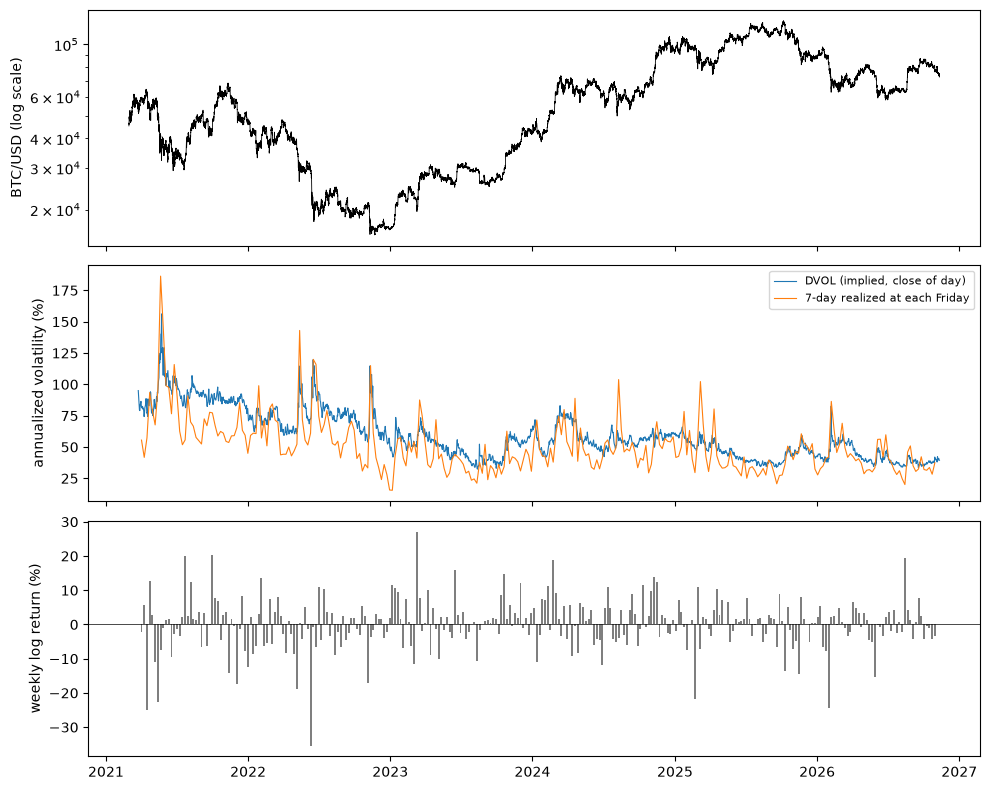

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(p.index, p.values, lw=0.6, color="black")
ax[0].set_yscale("log")
ax[0].set_ylabel("BTC/USD (log scale)")
ax[1].plot(dvol.index + pd.Timedelta(days=1), dvol.close, lw=0.8, label="DVOL (implied, close of day)")
ax[1].plot(w.t0, w.rv7 * 100, lw=0.8, label="7-day realized at each Friday")
ax[1].set_ylabel("annualized volatility (%)")
ax[1].legend(loc="upper right", fontsize=8)
ax[2].bar(w.t0, w.r * 100, width=5, color="tab:gray")
ax[2].axhline(0, color="black", lw=0.5)
ax[2].set_ylabel("weekly log return (%)")
fig.tight_layout()
fig.savefig(FIG / "raw_covered_call.png", dpi=150)
plt.show()

In [5]:
summary = w[["r", "dvol", "rv7", "rv30"]].describe(percentiles=[0.1, 0.5, 0.9]).T
summary = summary.rename(columns={"count": "n", "10%": "p10", "50%": "median", "90%": "p90"})
display(summary[["n", "mean", "std", "min", "p10", "median", "p90", "max"]].round(3))

,n,mean,std,min,p10,median,p90,max
r,292.0,0.001,0.074,-0.354,-0.075,0.007,0.082,0.271
dvol,292.0,0.592,0.186,0.336,0.385,0.550,0.873,1.198
rv7,292.0,0.506,0.219,0.155,0.294,0.455,0.763,1.864
rv30,292.0,0.527,0.182,0.254,0.327,0.502,0.722,1.368


## Split

The decision is about a later time, so the last year is held out: the last 52 weekly windows, the Fridays from the cutoff below onward. Nothing is fit, scaled, or chosen on those rows. Training windows all end on or before the cutoff. The cutoff is recorded in `decisions.md`.

In [6]:
N_HOLD = 52
train, test = w.iloc[:-N_HOLD].copy(), w.iloc[-N_HOLD:].copy()
CUTOFF = test.t0.iloc[0]
assert train["T"].max() <= CUTOFF and train.t0.max() < CUTOFF
print(f"train {len(train)} windows ({train.t0.iloc[0]:%Y-%m-%d} to {train.t0.iloc[-1]:%Y-%m-%d}); "
      f"held out {len(test)} windows (from {CUTOFF:%Y-%m-%d} to {test.t0.iloc[-1]:%Y-%m-%d})")
display(pd.concat({"train": train[["r", "dvol", "rv7", "rv30"]].agg(["mean", "std"]),
                   "held out": test[["r", "dvol", "rv7", "rv30"]].agg(["mean", "std"])}).round(3))

train 240 windows (2021-04-02 to 2025-10-31); held out 52 windows (from 2025-11-07 to 2026-10-30)


r   dvol    rv7   rv30
train    mean  0.002  0.626  0.526  0.548
         std   0.076  0.185  0.230  0.190
held out mean -0.006  0.438  0.416  0.431
         std   0.064  0.082  0.125  0.094

## Decision rule and loss

**Premium and payout.** For one coin of cover, a call struck at $K = S_0 e^{q}$ pays out $\max(S_T - K, 0)/S_T = (1 - e^{q - R})^+$ in BTC, where $R = \log(S_T/S_0)$. The premium is the Black-Scholes call price at zero rate, with $\sigma$ the previous day's DVOL and $T = 7/365$, divided by $S_0$ to give BTC: $p(q)$. The BTC gained from writing one call against one coin is

$$g(q, R) = p(q) - (1 - e^{q - R})^+ .$$

**Strike: the critical fractile.** Given a predictive distribution for $R$, the strike maximizes the expected gain $E[g(q, R)]$. Setting the derivative to zero, with $p'(q) = -e^{q} N(d_2)$, gives

$$N(d_2(q)) = E\left[\frac{S_0}{S_T}\,\mathbf 1\{S_T > K\}\right].$$

The right side is the forecast chance of finishing above the strike, weighted by the payout's $S_0/S_T$. The left side is the chance the premium's slope implies. The strike is where they are equal. A strike set too low costs more, since a rally pays out more than the premium collects, and that cost is what picks the number: no fixed fractile such as 0.9 appears. The strike is searched on a grid from at the money ($q = 0$) to 30 percent above, in steps of 0.005.

**Fraction written: Kelly.** After the strike is chosen, writing a fraction $f$ of the stack gives wealth per coin $W = 1 + f\,g$ next week. The fraction maximizes the average of $\log W$ over draws of $R$ from the predictive distribution, over $f \in [0, 1]$ in steps of 0.01. Zero is holding and one is a fully covered call. The win-or-lose Kelly formula does not apply, since the loss is continuous and occurs only above the strike. The edge is estimated and full Kelly overbets when it is noisy, so half of that fraction is reported too.

**Score.** The growth of the week is $\log W$ with the realized return, and the score is its mean over the held-out Fridays, against holding ($f = 0$, growth 0) and against writing a full call every week ($f = 1$). The rule is frozen on the training windows. Consecutive Friday-to-Friday returns do not overlap, so the 52 held-out Fridays are scored one by one. Their forecast inputs do overlap (DVOL and realized volatility move slowly), so the standard errors treat weeks as independent and are probably a little too small.

In [7]:
T_WEEK = 7 / 365
Q = np.arange(0, 0.3001, 0.005)   # strike grid: K = S0 * exp(q)
F = np.linspace(0, 1, 101)        # fraction of the stack written


def premium(dvol):
    """Black-Scholes call price in BTC per coin (S0 = 1, zero rate), for each strike in Q."""
    s = (np.asarray(dvol) * np.sqrt(T_WEEK))[:, None]
    d1 = (-Q[None, :] + 0.5 * s**2) / s
    return norm.cdf(d1) - np.exp(Q)[None, :] * norm.cdf(d1 - s)


def plan(dvol, R):
    """Strike and fraction from draws R (weeks x draws) of the 7-day log return."""
    prem = premium(dvol)
    payout = np.maximum(0, 1 - np.exp(Q[None, :, None] - R[:, None, :])).mean(axis=2)
    exp_gain = prem - payout
    i = exp_gain.argmax(axis=1)
    q, rows = Q[i], np.arange(len(i))
    pr = prem[rows, i]
    g = pr[:, None] - np.maximum(0, 1 - np.exp(q[:, None] - R))
    log_growth = np.log1p(F[None, :, None] * g[:, None, :]).mean(axis=2)
    s = np.asarray(dvol) * np.sqrt(T_WEEK)
    return pd.DataFrame({
        "q": q, "f": F[log_growth.argmax(axis=1)], "prem": pr, "exp_gain": exp_gain[rows, i],
        "p_exceed": (R > q[:, None]).mean(axis=1),
        "p_weighted": (np.exp(-R) * (R > q[:, None])).mean(axis=1),
        "p_premium": norm.cdf((-q - 0.5 * s**2) / s),
    })


def growth(df, pl, f):
    """Realized log growth of the stack for fraction f, and the gain g, in each week."""
    g = pl.prem.values - np.maximum(0, 1 - np.exp(pl.q.values - df.r.values))
    return np.log1p(f * g), g

## Baseline: DVOL alone

If next week's log return were normal with zero mean and the volatility DVOL says, $R \sim N(0,\ \mathrm{DVOL}^2 \cdot 7/365)$. The baseline applies the same rule to that distribution, represented by 2,000 equally spaced quantiles.

The premium is priced at the same DVOL, so under the baseline's own distribution the premium is close to fair, and the strike is chosen where the small remaining edge is largest.

In [8]:
M_BASE = 2000
R_base = norm.ppf((np.arange(M_BASE) + 0.5) / M_BASE)[None, :] * test.d.values[:, None]
pl_base = plan(test.dvol.values, R_base)
print(f"baseline plan, held out: mean strike {100 * (np.exp(pl_base.q) - 1).mean():.1f}% out of the money, "
      f"mean fraction {pl_base.f.mean():.2f}; strikes at the at-the-money edge of the grid in {(pl_base.q == 0).mean():.0%} of weeks")

baseline plan, held out: mean strike 0.0% out of the money, mean fraction 0.76; strikes at the at-the-money edge of the grid in 100% of weeks


## Model: location-scale model with empirical shape

$$r_t = \mu + \sigma_t\,z_t, \qquad \log \sigma_t = \alpha + \beta \log d_t + \gamma \log x_t,$$

where $d_t$ is DVOL and $x_t$ is realized volatility, both scaled to one week. The parameters $(\mu, \alpha, \beta, \gamma)$ are fit by Gaussian quasi-likelihood on the training windows (`scipy.optimize.minimize`). The standardized residuals $z_t = (r_t - \hat\mu)/\hat\sigma_t$ are kept as they are: the predictive distribution for a new Friday is $\hat\mu + \hat\sigma_t z_j$ over the training residuals $z_j$, which carries the skew and the thick tails of the data instead of assuming a normal shape.

- $\mu$: the typical weekly log return (bitcoin's drift).
- $\alpha$: the base level of weekly volatility when both inputs are one.
- $\beta$: how much of DVOL's movement passes into next week's volatility. The baseline is $\alpha = 0$, $\beta = 1$, $\gamma = 0$, $\mu = 0$ with a normal shape.
- $\gamma$: what trailing realized volatility adds once DVOL is known. The hypothesis is that $\gamma \neq 0$ helps.

The realized-volatility window, 7 or 30 days, is chosen on training windows only: for each of the last 52 training weeks, fit on all earlier training weeks and score that week by the Gaussian log score. The assumption trusted least is the Black-Scholes premium (30-day DVOL for 7-day options, no skew or spread). After it, the shape of $z$ is assumed stable over time and independent of the inputs, estimated from 240 windows.

**Uncertainty.** Every forecast is a predictive distribution, and calibration is checked below on the held-out weeks. Pairs bootstrap of the training windows (300 draws, seed `SEED`) gives intervals for the parameters.

In [9]:
def sigma_of(th, df, x):
    return np.exp(th[1] + th[2] * np.log(df.d) + th[3] * np.log(df[x]))


def nll(th, df, x):
    s = sigma_of(th, df, x)
    return np.sum(np.log(s) + (df.r - th[0]) ** 2 / (2 * s**2))


def fit_scale(df, x):
    th0 = np.array([df.r.mean(), 0.0, 1.0, 0.0])   # start at the baseline
    return minimize(nll, th0, args=(df, x), method="BFGS").x


# choose the realized-volatility window on training windows only
cv = {}
for x in ["x7", "x30"]:
    score = []
    for i in range(len(train) - 52, len(train)):
        past, nxt = train.iloc[:i], train.iloc[[i]]
        th = fit_scale(past, x)
        s = sigma_of(th, nxt, x).values[0]
        score.append(np.log(s) + (nxt.r.values[0] - th[0]) ** 2 / (2 * s**2))
    cv[x] = np.mean(score)
last = train.iloc[-52:]
cv["baseline (DVOL alone)"] = np.mean(np.log(last.d) + last.r**2 / (2 * last.d**2))
print("training-only Gaussian negative log score, last 52 training weeks (lower is better):",
      {k: round(v, 4) for k, v in cv.items()})
X_RV = min(["x7", "x30"], key=cv.get)
print("realized-volatility window chosen:", X_RV)

theta = fit_scale(train, X_RV)
z = ((train.r - theta[0]) / sigma_of(theta, train, X_RV)).values
print(f"fit: mu = {theta[0]:+.4f}, alpha = {theta[1]:+.3f}, beta = {theta[2]:+.3f}, gamma = {theta[3]:+.3f}")
print(f"standardized residuals: mean {z.mean():+.3f}, sd {z.std():.3f}, skew {pd.Series(z).skew():+.2f}, 90th percentile {np.quantile(z, 0.9):.2f} (normal: 1.28)")

training-only Gaussian negative log score, last 52 training weeks (lower is better): {'x7': np.float64(-2.2806), 'x30': np.float64(-2.2721), 'baseline (DVOL alone)': np.float64(-2.2919)}
realized-volatility window chosen: x7
fit: mu = +0.0038, alpha = -1.598, beta = +0.633, gamma = -0.213
standardized residuals: mean -0.011, sd 1.000, skew -0.30, 90th percentile 1.21 (normal: 1.28)


In [10]:
NB = 300
boot = np.empty((NB, 4))
for i in range(NB):
    boot[i] = fit_scale(train.iloc[rng.integers(0, len(train), len(train))], X_RV)
coef = pd.DataFrame({"estimate": theta, "boot SE": boot.std(0),
                     "5%": np.percentile(boot, 5, 0), "95%": np.percentile(boot, 95, 0)},
                    index=["mu", "alpha", "beta (on DVOL)", "gamma (on realized vol)"])
display(coef.round(4))

,estimate,boot SE,5%,95%
mu,0.0038,0.0048,-0.0035,0.0120
alpha,-1.5983,0.5938,-2.4842,-0.6032
beta (on DVOL),0.6334,0.3018,0.2035,1.1768
gamma (on realized vol),-0.2130,0.2282,-0.5763,0.1707


In [11]:
sig_te = sigma_of(theta, test, X_RV).values
R_model = theta[0] + sig_te[:, None] * z[None, :]
pl_model = plan(test.dvol.values, R_model)
near = pl_model.q < 0.05
print(f"model plan, held out: strike within 5% of the money in {near.mean():.0%} of weeks (mean fraction there {pl_model.f[near].mean():.2f}), "
      f"and {100 * (np.exp(pl_model.q[~near].min()) - 1):.0f} to {100 * (np.exp(pl_model.q.max()) - 1):.0f}% above spot in the other weeks "
      f"(mean fraction {pl_model.f[~near].mean():.2f}); overall mean fraction {pl_model.f.mean():.2f}")
dv, nr = test.dvol.values, near.values
print(f"DVOL in the near-the-money weeks: {dv[nr].min():.2f} to {dv[nr].max():.2f}; in the others: {dv[~nr].min():.2f} to {dv[~nr].max():.2f}")

model plan, held out: strike within 5% of the money in 56% of weeks (mean fraction there 0.87), and 23 to 29% above spot in the other weeks (mean fraction 1.00); overall mean fraction 0.93
DVOL in the near-the-money weeks: 0.39 to 0.83; in the others: 0.34 to 0.43


## Scores on the held-out year

The rule is frozen: parameters, window and residuals come from the training windows only. Growth is $\log W$ per week, in BTC per coin held, so 0.001 a week is about 5 percent over 52 weeks. All premiums are Black-Scholes at DVOL.

In [12]:
N = len(test)
ones, zeros = np.ones(N), np.zeros(N)
# a naive comparator: a fixed strike about 10% out of the money (grid point 9.5%), set before looking at results
i10 = np.argmin(np.abs(Q - 0.095))
pl_fixed = pd.DataFrame({"q": np.full(N, Q[i10]), "prem": premium(test.dvol.values)[:, i10]})
strategies = {
    "Hold (do not sell)":              (None, zeros),
    "Full call, model strike":         (pl_model, ones),
    "Model, Kelly fraction":           (pl_model, pl_model.f.values),
    "Model, half Kelly":               (pl_model, pl_model.f.values / 2),
    "Full call, fixed 10% strike":     (pl_fixed, ones),
    "Full call, DVOL strike":          (pl_base, ones),
    "DVOL baseline, Kelly fraction":   (pl_base, pl_base.f.values),
    "DVOL baseline, half Kelly":       (pl_base, pl_base.f.values / 2),
}
lg, rows = {}, {}
for name, (pl, f) in strategies.items():
    lg[name] = np.zeros(N) if pl is None else growth(test, pl, f)[0]
    rows[name] = {
        "mean fraction": f.mean(),
        "weeks within 5% of the money": np.nan if pl is None else np.mean(pl.q < 0.05),
        "mean strike, % above spot": np.nan if pl is None else 100 * (np.exp(pl.q) - 1).mean(),
        "growth per week": lg[name].mean(),
        "SE": lg[name].std(ddof=1) / np.sqrt(N),
        "total, 52 weeks": lg[name].sum(),
        "worst week": lg[name].min(),
    }
scores = pd.DataFrame(rows).T
display(scores.round(5))

pairs = [("Model Kelly - Hold", "Model, Kelly fraction", "Hold (do not sell)"),
         ("Model half Kelly - Hold", "Model, half Kelly", "Hold (do not sell)"),
         ("Model Kelly - full call, model strike", "Model, Kelly fraction", "Full call, model strike"),
         ("Model Kelly - DVOL baseline Kelly", "Model, Kelly fraction", "DVOL baseline, Kelly fraction"),
         ("Model Kelly - full call, DVOL strike", "Model, Kelly fraction", "Full call, DVOL strike"),
         ("Full call, model strike - full call, fixed 10% strike", "Full call, model strike", "Full call, fixed 10% strike")]
diffs = {}
for label, a, b in pairs:
    dlt = lg[a] - lg[b]
    diffs[label] = {"mean": dlt.mean(), "paired SE": dlt.std(ddof=1) / np.sqrt(N), "better in": np.mean(dlt > 0)}
display(pd.DataFrame(diffs).T.round(5))

,mean fraction,weeks within 5% of the money,"mean strike, % above spot",growth per week,SE,"total, 52 weeks",worst week
Hold (do not sell),0.00000,NaN,NaN,0.00000,0.00000,0.00000,0.00000
"Full call, model strike",1.00000,0.55769,12.36833,0.00521,0.00195,0.27107,-0.04011
"Model, Kelly fraction",0.92962,0.55769,12.36833,0.00526,0.00183,0.27350,-0.04011
"Model, half Kelly",0.46481,0.55769,12.36833,0.00265,0.00092,0.13804,-0.01985
"Full call, fixed 10% strike",1.00000,0.00000,9.96589,-0.00003,0.00195,-0.00163,-0.09826
"Full call, DVOL strike",1.00000,1.00000,0.00000,0.00622,0.00453,0.32330,-0.17070
"DVOL baseline, Kelly fraction",0.75615,1.00000,0.00000,0.00483,0.00337,0.25129,-0.12522
"DVOL baseline, half Kelly",0.37808,1.00000,0.00000,0.00249,0.00166,0.12956,-0.06065


,mean,paired SE,better in
Model Kelly - Hold,0.00526,0.00183,0.84615
Model half Kelly - Hold,0.00265,0.00092,0.84615
"Model Kelly - full call, model strike",0.00005,0.00049,0.07692
Model Kelly - DVOL baseline Kelly,0.00043,0.00294,0.44231
"Model Kelly - full call, DVOL strike",-0.00096,0.00399,0.36538
"Full call, model strike - full call, fixed 10% strike",0.00524,0.00261,0.42308


### What the scores say

Numbers below are from the run saved with this notebook. All gains are at Black-Scholes premiums, not fills.

- **Against holding.** The model's strikes with Kelly fractions grew the stack by 0.0053 log BTC per coin per week (SE 0.0018), 0.27 over the 52 weeks (about 31 percent more bitcoin), and were ahead of holding in 85 percent of weeks. The year was one where bitcoin fell on average (mean weekly return -0.6 percent), so most written calls expired worthless. A rising year would look different.
- **The strike choice carries the result.** A full call at a fixed strike about 10 percent out of the money earned nothing (-0.00003 a week), and a full call at the model's strikes earned 0.0052 more per week (paired SE 0.0026, about two standard errors). The rule is close to binary. In 56 percent of weeks (DVOL 0.39 to 0.83) it writes within 5 percent of the money, where the premium looks rich against the model's distribution. In the other weeks (DVOL 0.34 to 0.43) it writes 23 to 29 percent above spot, where there is little edge and little at stake. The mean strike, 12 percent, describes neither group.
- **Sizing adds nothing here.** The Kelly fraction is 0.93 on average and at least 0.9 in 87 percent of weeks, so Kelly growth equals the full call's (difference +0.00005, SE 0.0005). Half Kelly gives half the growth (0.0027) and half the worst week (-2.0 percent against -4.0 percent).
- **Against DVOL alone: a tie on growth.** The model's Kelly rule is ahead of the baseline's by 0.0004 a week (SE 0.0029). The baseline writes at the money every week, because its normal distribution with zero drift makes that strike the most valuable, at an average fraction of 0.76. Its growth is far more variable (a worst week of -12.5 percent against -4.0 percent for the model, and -17.1 percent for a full at-the-money call), so the model's rule earns similar growth with smaller swings. That difference comes from the strike and the fraction the two distributions imply, not demonstrably from realized volatility.
- **Realized volatility does not help on these data.** $\gamma = -0.21$ with a 90 percent bootstrap interval of [-0.58, +0.17]. On the last 52 training weeks the baseline's Gaussian log score (-2.292) was better than the model's (-2.281 with the 7-day window). The hypothesis that realized volatility adds to DVOL is not supported.

### Does the strike satisfy the critical-fractile condition?

At an interior strike on the grid, the forecast's weighted exceedance chance should equal the chance the premium implies, $N(d_2)$. The grid has a step of 0.005 and the model's distribution has 240 points, so the match is approximate. The baseline sits at the edge of the grid (at the money), where the condition does not have to hold.

In [13]:
for name, pl in [("model", pl_model), ("DVOL baseline", pl_base)]:
    interior = (pl.q > 0) & (pl.q < Q[-1])
    if interior.sum() == 0:
        print(f"{name}: no interior strikes; every strike is at the at-the-money edge of the grid, so the condition does not apply")
        continue
    gap = (pl.p_weighted - pl.p_premium)[interior]
    print(f"{name}: interior strikes in {interior.mean():.0%} of weeks; forecast weighted exceedance {pl.p_weighted[interior].mean():.3f} "
          f"vs premium-implied {pl.p_premium[interior].mean():.3f}; mean gap {gap.mean():+.4f}, mean |gap| {gap.abs().mean():.4f}; "
          f"forecast exceedance probability at the strike {pl.p_exceed.mean():.3f}")

model: interior strikes in 100% of weeks; forecast weighted exceedance 0.223 vs premium-implied 0.221; mean gap +0.0020, mean |gap| 0.0028; forecast exceedance probability at the strike 0.236
DVOL baseline: no interior strikes; every strike is at the at-the-money edge of the grid, so the condition does not apply


In [14]:
# the model's own expected gain, at its chosen strikes and at the fixed strike
eg10 = premium(test.dvol.values)[:, i10] - np.maximum(0, 1 - np.exp(Q[i10] - R_model)).mean(axis=1)
print(f"model's expected gain per week: at the chosen strikes {pl_model.exp_gain.mean():.5f}, "
      f"at a fixed strike {100 * (np.exp(Q[i10]) - 1):.1f}% above spot {eg10.mean():.5f}")

model's expected gain per week: at the chosen strikes 0.00178, at a fixed strike 10.0% above spot -0.00038


### Reading the critical-fractile check

The condition holds for the model. In all 52 weeks the strike is inside the grid, the forecast's weighted exceedance chance averages 0.223 and the chance the premium implies averages 0.221 (mean gap +0.002). Written another way, the forecast chance of finishing above the strike is about 24 percent. That is far from a fixed 10 percent, and it is what the premium and the payout choose. The baseline sits at the edge of the grid in every week, where the condition does not have to hold.

## Residuals and calibration

For each held-out week the probability integral transform (PIT) is $u_t = F_t(r_t)$, the share of the predictive draws at or below the realized return. If the predictive distribution is calibrated, the $u_t$ are uniform on $[0, 1]$: 10 percent of them fall above 0.9, and so on. A pile at the top means the forecast was too low, a pile at the bottom too high. The standardized residual $z_t$ shows whether the model's scale tracks the data over time.

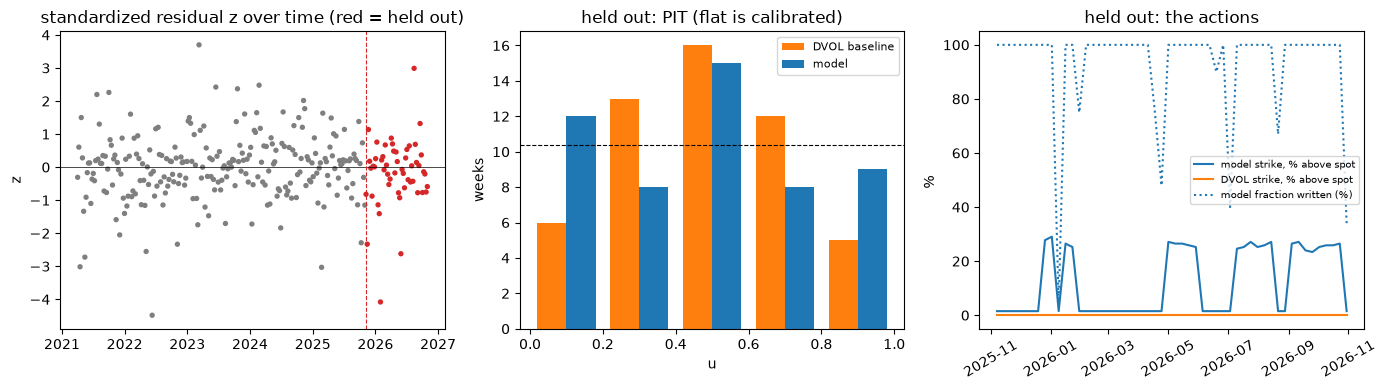

In [15]:
u_model = (R_model <= test.r.values[:, None]).mean(axis=1)
u_base = (R_base <= test.r.values[:, None]).mean(axis=1)
z_all = ((pd.concat([train, test]).r - theta[0]) / sigma_of(theta, pd.concat([train, test]), X_RV)).values
t_all = pd.concat([train, test]).t0

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].scatter(t_all, z_all, s=8, c=np.where(t_all >= CUTOFF, "tab:red", "tab:gray"))
ax[0].axhline(0, color="black", lw=0.5)
ax[0].axvline(CUTOFF, color="tab:red", ls="--", lw=0.8)
ax[0].set(title="standardized residual z over time (red = held out)", ylabel="z")
bins = np.linspace(0, 1, 6)
ax[1].hist([u_base, u_model], bins=bins, color=["tab:orange", "tab:blue"], label=["DVOL baseline", "model"])
ax[1].axhline(N / 5, color="black", ls="--", lw=0.8)
ax[1].set(title="held out: PIT (flat is calibrated)", xlabel="u", ylabel="weeks")
ax[1].legend(fontsize=8)
ax[2].plot(test.t0, 100 * (np.exp(pl_model.q) - 1), color="tab:blue", label="model strike, % above spot")
ax[2].plot(test.t0, 100 * (np.exp(pl_base.q) - 1), color="tab:orange", label="DVOL strike, % above spot")
ax[2].plot(test.t0, 100 * pl_model.f, color="tab:blue", ls=":", label="model fraction written (%)")
ax[2].set(title="held out: the actions", ylabel="% ")
ax[2].legend(fontsize=7)
ax[2].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG / "residuals_covered_call.png", dpi=150)
plt.show()

In [16]:
taus = [0.1, 0.25, 0.5, 0.75, 0.9]
cal = pd.DataFrame({"model": [np.mean(u_model <= t) for t in taus], "DVOL baseline": [np.mean(u_base <= t) for t in taus]},
                   index=[f"share of weeks with u <= {t}" for t in taus])
cal.loc["share of weeks with u > 0.9 (upper tail)"] = [np.mean(u_model > 0.9), np.mean(u_base > 0.9)]
display(cal.round(3))
print("expected 10% in the upper tail is", round(0.1 * N, 1), "of", N, "weeks; model:", int((u_model > 0.9).sum()),
      "baseline:", int((u_base > 0.9).sum()),
      "; binomial p-values", round(binomtest(int((u_model > 0.9).sum()), N, 0.1).pvalue, 3),
      round(binomtest(int((u_base > 0.9).sum()), N, 0.1).pvalue, 3))
half = N // 2
print("mean |PIT - 0.5|, first vs second half of held-out: model",
      round(np.abs(u_model[:half] - 0.5).mean(), 3), round(np.abs(u_model[half:] - 0.5).mean(), 3),
      "; baseline", round(np.abs(u_base[:half] - 0.5).mean(), 3), round(np.abs(u_base[half:] - 0.5).mean(), 3), "(uniform: 0.25)")
print("mean growth per week, first vs second half of held-out: model Kelly",
      round(lg["Model, Kelly fraction"][:half].mean(), 5), round(lg["Model, Kelly fraction"][half:].mean(), 5))

,model,DVOL baseline
share of weeks with u <= 0.1,0.096,0.077
share of weeks with u <= 0.25,0.269,0.231
share of weeks with u <= 0.5,0.615,0.500
share of weeks with u <= 0.75,0.769,0.846
share of weeks with u <= 0.9,0.962,0.962
share of weeks with u > 0.9 (upper tail),0.038,0.038


expected 10% in the upper tail is 5.2 of 52 weeks; model: 2 baseline: 2 ; binomial p-values 0.168 0.168
mean |PIT - 0.5|, first vs second half of held-out: model 0.23 0.23 ; baseline 0.204 0.211 (uniform: 0.25)
mean growth per week, first vs second half of held-out: model Kelly 0.00762 0.0029


### Reading the calibration

- **Tails.** Both predictive distributions were exceeded in the upper tail (above the 90th percentile) in 2 of 52 weeks, against about 5 expected (binomial p = 0.17). That is not a detectable miscalibration, but the upper tail was a little thin in the held-out year, which helped call writers. The lower tail is close to nominal (model 9.6 percent below the 10th percentile, baseline 7.7 percent).
- **Noise or bias.** The model's realized returns fell below its median in 61.5 percent of weeks (32 of 52, p = 0.13 against one half), where the baseline's is exactly 50 percent. That is a mild upward bias of the model's median, from the fitted drift of +0.4 percent a week against a held-out mean of -0.6 percent. It is within noise for 52 weeks, but it points the same way as the falling market.
- **Error over the horizon.** The forecast horizon is fixed at one week, so there is no error-versus-horizon curve. From the first half of the held-out weeks to the second, the spread of the PIT is unchanged for the model (0.23 and 0.23) and the baseline (0.204 and 0.211), so neither forecast decayed. The model's Kelly growth was 0.0076 a week in the first half and 0.0029 in the second, which is noisy at 26 weeks each.

## Decision: how the action moves with the inputs

The table holds the model's inputs at their held-out medians and moves DVOL only, then does the same for realized volatility. Each row applies the frozen rule to a hypothetical Friday, with the premium priced at DVOL.

In [17]:
med_d, med_x = test.d.median(), test[X_RV].median()
med_dvol = test.dvol.median()


def what_if(dvols, xs):
    df = pd.DataFrame({"dvol": dvols, "d": np.asarray(dvols) * np.sqrt(T_WEEK), X_RV: np.asarray(xs) * np.sqrt(T_WEEK)})
    sg = sigma_of(theta, df, X_RV).values
    pl = plan(df.dvol.values, theta[0] + sg[:, None] * z[None, :])
    return pd.DataFrame({"strike, % above spot": 100 * (np.exp(pl.q.to_numpy()) - 1), "fraction written": pl.f.to_numpy(),
                         "expected gain, BTC/week": pl.exp_gain.to_numpy()}, index=np.round(dvols if len(set(dvols)) > 1 else xs, 2))


grid = np.array([0.30, 0.35, 0.38, 0.40, 0.42, 0.45, 0.50, 0.60, 0.80])
rv_med = test[X_RV].median() / np.sqrt(T_WEEK)
print(f"DVOL moves, realized vol fixed at its held-out median ({rv_med:.2f}); index = annualized DVOL")
display(what_if(grid, np.full(len(grid), rv_med)).round(4))
print(f"realized vol moves, DVOL fixed at its held-out median ({med_dvol:.2f}); index = annualized realized vol")
display(what_if(np.full(len(grid), med_dvol), grid).round(4))

DVOL moves, realized vol fixed at its held-out median (0.41); index = annualized DVOL


,"strike, % above spot",fraction written,"expected gain, BTC/week"
0.30,20.9250,1.00,0.0000
0.35,23.3678,1.00,0.0000
0.38,24.6077,1.00,0.0000
0.40,1.5113,0.26,0.0002
0.42,1.5113,0.71,0.0007
0.45,1.5113,1.00,0.0014
0.50,1.5113,1.00,0.0027
0.60,1.5113,1.00,0.0055
0.80,2.0201,1.00,0.0116


realized vol moves, DVOL fixed at its held-out median (0.42); index = annualized realized vol


,"strike, % above spot",fraction written,"expected gain, BTC/week"
0.30,28.4025,1.00,0.0000
0.35,1.5113,0.08,0.0001
0.38,1.5113,0.43,0.0004
0.40,1.5113,0.65,0.0007
0.42,1.5113,0.86,0.0009
0.45,1.5113,1.00,0.0011
0.50,1.5113,1.00,0.0016
0.60,1.5113,1.00,0.0023
0.80,1.5113,1.00,0.0034


### Reading the table

- **DVOL.** Below about 0.38 the rule writes far out of the money and the expected gain is zero to four decimals. At 0.40 it switches to a strike about 1.5 percent above spot, at a fraction of 0.26. The fraction rises to 1.0 by 0.45 and the expected gain grows from 0.0002 to 0.0116 BTC a week at 0.80. The model's scale grows only as DVOL to the power 0.63, so it treats high implied volatility as overpriced. That is the assumption that implied volatility stays above realized volatility after the training years, and it is worth testing for the final. Rows above the held-out range (the held-out maximum is 0.83) are extrapolation.
- **Realized volatility.** The fraction rises as realized volatility rises, from 0.08 at 0.35 to 1.0 at 0.45 and above. That is the sign of the fitted $\gamma = -0.21$: more realized volatility lowers the predicted volatility, which makes the premium look richer. Since $\gamma$ is not distinguishable from zero, this direction should not be trusted.

## Simulation check

Not part of the 18 November checkpoint. For the final: draw weekly returns from the fitted model with known parameters, refit, and show that the fit recovers them.

## Limits

(Draft, to be completed for the final.) Only 52 held-out weeks from one market regime, so differences of a few thousandths of growth per week cannot be told from noise. The premium is Black-Scholes at 30-day DVOL, not a traded price, and DVOL is also an input. What a better forecast would be worth, in BTC, is for the final.